# 02 EDA
Reads data.csv. Plots and quick checks only, nothing here goes into the model.

In [92]:
import pandas as pd
import numpy as np

In [93]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [94]:
BASE = '/content/drive/MyDrive/ml/weather'

In [95]:
data = pd.read_csv(f'{BASE}/data.csv', index_col=0, parse_dates=True)

In [96]:
data

,temp,humidity,precipitation,pressure,wind_speed,wind_dir,wind_gusts,cloud_cover,pm10,pm2.5,so2,co,no2
2020-09-05 20:00:00,21.4,53,0.0,915.7,18.5,327,37.8,1,3.59,3.15,2.03,410.45,19.98
2020-09-05 21:00:00,20.1,58,0.0,916.1,15.3,341,34.2,0,10.86,3.08,1.80,371.99,18.40
2020-09-05 22:00:00,19.0,61,0.0,916.3,10.0,345,28.1,0,8.73,2.20,1.54,337.28,21.06
2020-09-05 23:00:00,18.2,64,0.0,916.1,7.2,333,19.4,0,7.22,1.71,1.31,312.34,21.14
2020-09-06 00:00:00,17.5,67,0.0,916.1,5.9,308,14.8,0,5.91,3.23,1.11,298.79,23.24
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-30 19:00:00,14.2,81,0.0,920.1,11.7,49,27.0,38,13.74,5.19,3.04,355.15,32.49
2026-09-30 20:00:00,13.4,76,0.0,920.4,12.2,47,28.1,47,12.93,5.83,2.97,349.24,27.80
2026-09-30 21:00:00,13.2,75,0.0,920.3,10.2,46,27.7,39,13.05,6.76,3.21,315.83,21.66
2026-09-30 22:00:00,12.7,76,0.0,920.6,8.7,42,22.3,23,13.35,6.45,3.10,332.69,22.99


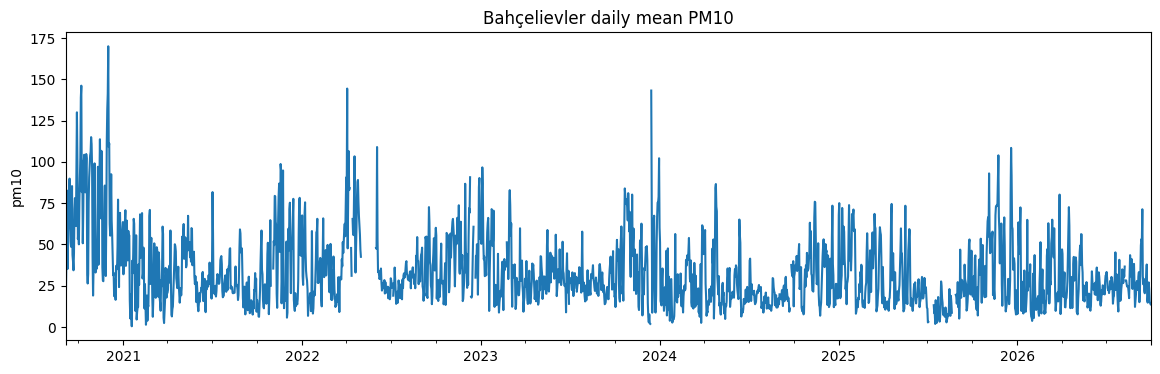

In [97]:
daily = data['pm10'].resample('D').mean()
import matplotlib.pyplot as plt
daily.plot(figsize=(14,4))
plt.ylabel('pm10')
plt.title('Bahçelievler daily mean PM10')
plt.show()

Every year PM10 rises in late autumn / early winter and drops to its lowest in summer.
There are gaps around May 2022 and summer 2025.
Late 2020 looks different from other years, always 50 or higher. Could be real pollution or a sensor change.
Some days are close to zero, probably measurement errors.
Spikes in late 2020, spring 2022 and late 2023.

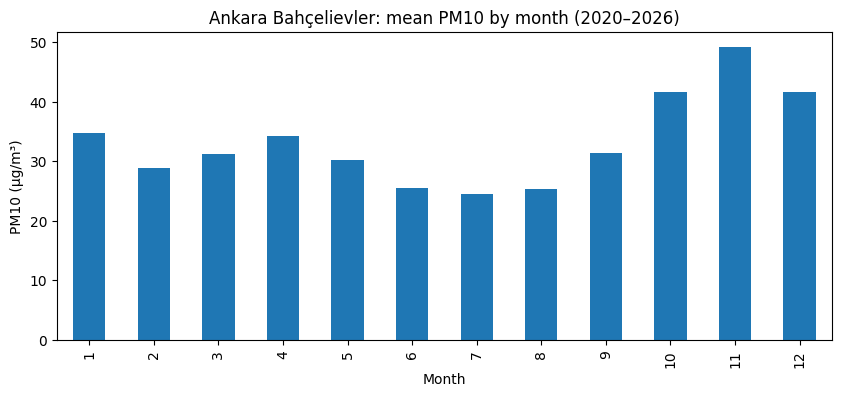

In [98]:
monthly = data["pm10"].groupby(data.index.month).mean()

monthly.plot(kind="bar", figsize=(10, 4))
plt.title("Ankara Bahçelievler: mean PM10 by month (2020–2026)")
plt.xlabel("Month")
plt.ylabel("PM10 (µg/m³)")
plt.savefig(f'{BASE}/figures/monthly_pm10.png', dpi=150, bbox_inches='tight')
plt.show()

In [99]:
data[data['pm10']>300]

,temp,humidity,precipitation,pressure,wind_speed,wind_dir,wind_gusts,cloud_cover,pm10,pm2.5,so2,co,no2
2021-01-27 15:00:00,9.4,59,0.0,902.2,20.4,206,62.3,99,357.43,15.17,1.12,222.36,29.63
2021-07-03 18:00:00,24.2,53,0.0,909.5,16.9,308,35.6,95,310.55,22.26,1.67,119.59,52.00
2021-12-07 21:00:00,11.9,46,0.0,905.0,22.2,148,42.8,87,393.41,62.83,3.14,252.72,24.92
2021-12-07 22:00:00,11.4,47,0.0,904.8,19.7,145,42.1,99,434.52,75.65,3.54,228.14,18.16
2022-02-28 20:00:00,4.9,93,0.6,914.5,17.8,256,31.0,100,419.81,17.77,3.31,1206.56,119.12
2022-11-17 10:00:00,8.2,44,0.0,913.2,3.6,264,12.2,95,419.62,28.32,3.75,NaN,218.62
2022-12-28 21:00:00,3.0,80,0.0,925.2,3.8,131,6.1,1,541.96,376.51,5.91,NaN,182.44


In [100]:
daily_stats = data['pm10'].resample('D').agg(['mean', 'count'])

(array([ 1.,  2.,  2.,  4.,  2.,  3.,  3.,  3.,  3., 50.]),
 array([ 1. ,  3.3,  5.6,  7.9, 10.2, 12.5, 14.8, 17.1, 19.4, 21.7, 24. ]),
 <BarContainer object of 10 artists>)

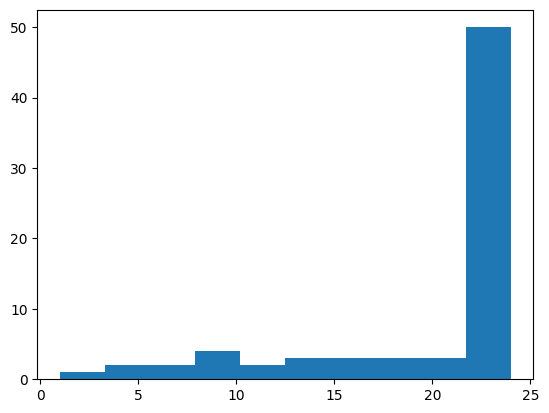

In [101]:
count_stats = daily_stats[daily_stats['mean']<8]
plt.hist(count_stats['count'])

In [102]:
sum(count_stats['count'] < 18)

17

In [103]:
sum(daily_stats['count'] < 18)

133

In [104]:
cond = daily_stats['count'] < 18
daily_stats.loc[cond, 'mean'] = np.nan

In [105]:
daily_stats['mean'].isna().sum()

np.int64(133)

In [106]:
cond.sum()

np.int64(133)

<Axes: >

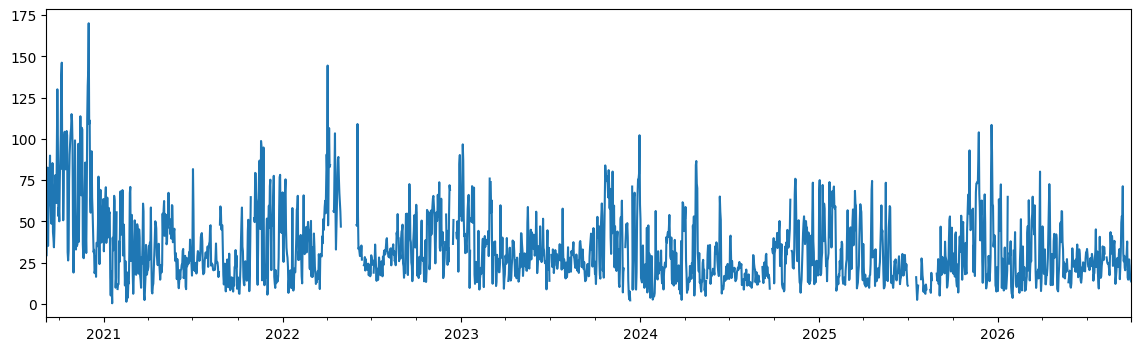

In [107]:
daily_stats['mean'].plot(figsize=(14, 4))


Days with fewer than 18 hourly measurements were set to NaN. That is 133 days, mostly around May 2022 and August 2025.

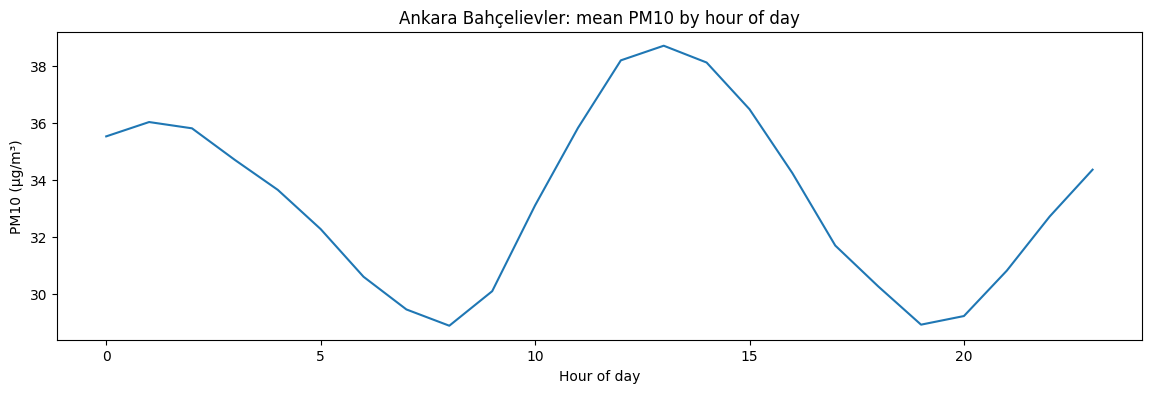

In [108]:
hourly = data['pm10'].groupby(data.index.hour).mean()
hourly.plot(figsize=(14, 4))
plt.xlabel('Hour of day')
plt.ylabel('PM10 (µg/m³)')
plt.title('Ankara Bahçelievler: mean PM10 by hour of day')
plt.savefig(f'{BASE}/figures/hourly_pm10.png', dpi=150, bbox_inches='tight')
plt.show()


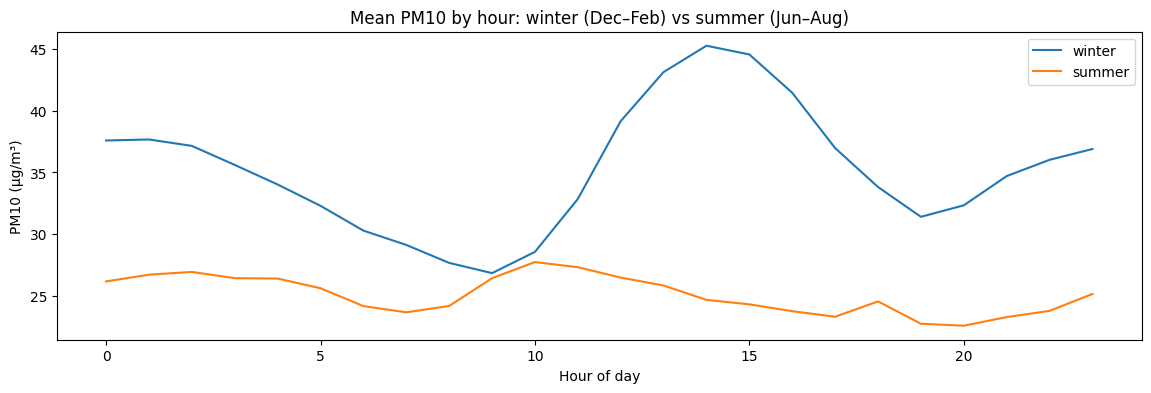

In [109]:
winter = data.index.month.isin([1, 2, 12])
winter_df = data.loc[winter, 'pm10']
winter_df = winter_df.groupby(winter_df.index.hour).mean().rename('pm10_mean')

summer = data.index.month.isin([6, 7, 8])
summer_df = data.loc[summer, 'pm10']
summer_df = summer_df.groupby(summer_df.index.hour).mean().rename('pm10_mean')

winter_df.plot(figsize=(14, 4), label='winter')
summer_df.plot(figsize=(14 ,4), label='summer')
plt.xlabel('Hour of day')
plt.ylabel('PM10 (µg/m³)')
plt.title('Mean PM10 by hour: winter (Dec–Feb) vs summer (Jun–Aug)')
plt.legend()
plt.savefig(f'{BASE}/figures/winter_sum_hourly.png', dpi=150, bbox_inches='tight')
plt.show()

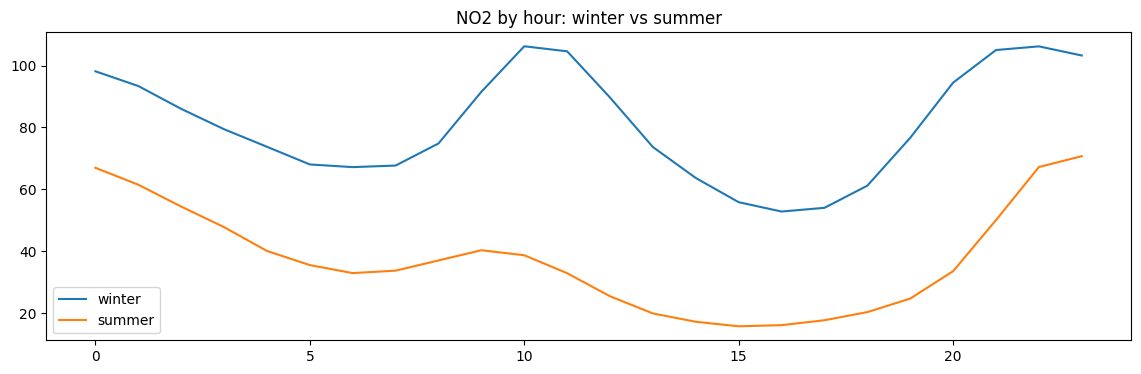

In [110]:
winter_no2 = data.loc[winter, 'no2']
winter_no2_h = winter_no2.groupby(winter_no2.index.hour).mean()

summer_no2 = data.loc[summer, 'no2']
summer_no2_h = summer_no2.groupby(summer_no2.index.hour).mean()

winter_no2_h.plot(figsize=(14, 4), label='winter')
summer_no2_h.plot(figsize=(14, 4), label='summer')
plt.title('NO2 by hour: winter vs summer')
plt.legend()

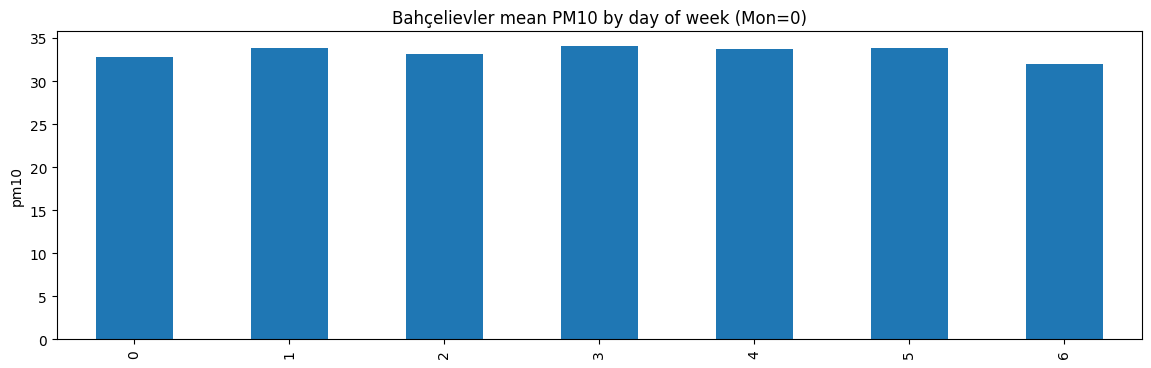

In [111]:
weekly = data['pm10'].groupby(data.index.dayofweek).mean()
weekly.plot(figsize=(14, 4), kind='bar')
plt.ylabel('pm10')
plt.title('Bahçelievler mean PM10 by day of week (Mon=0)')
plt.show()

Day of week has almost no effect on PM10.

<Axes: >

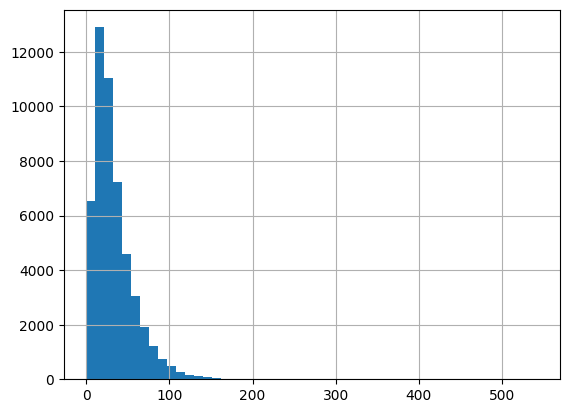

In [112]:
data['pm10'].hist(bins=50)

<Axes: >

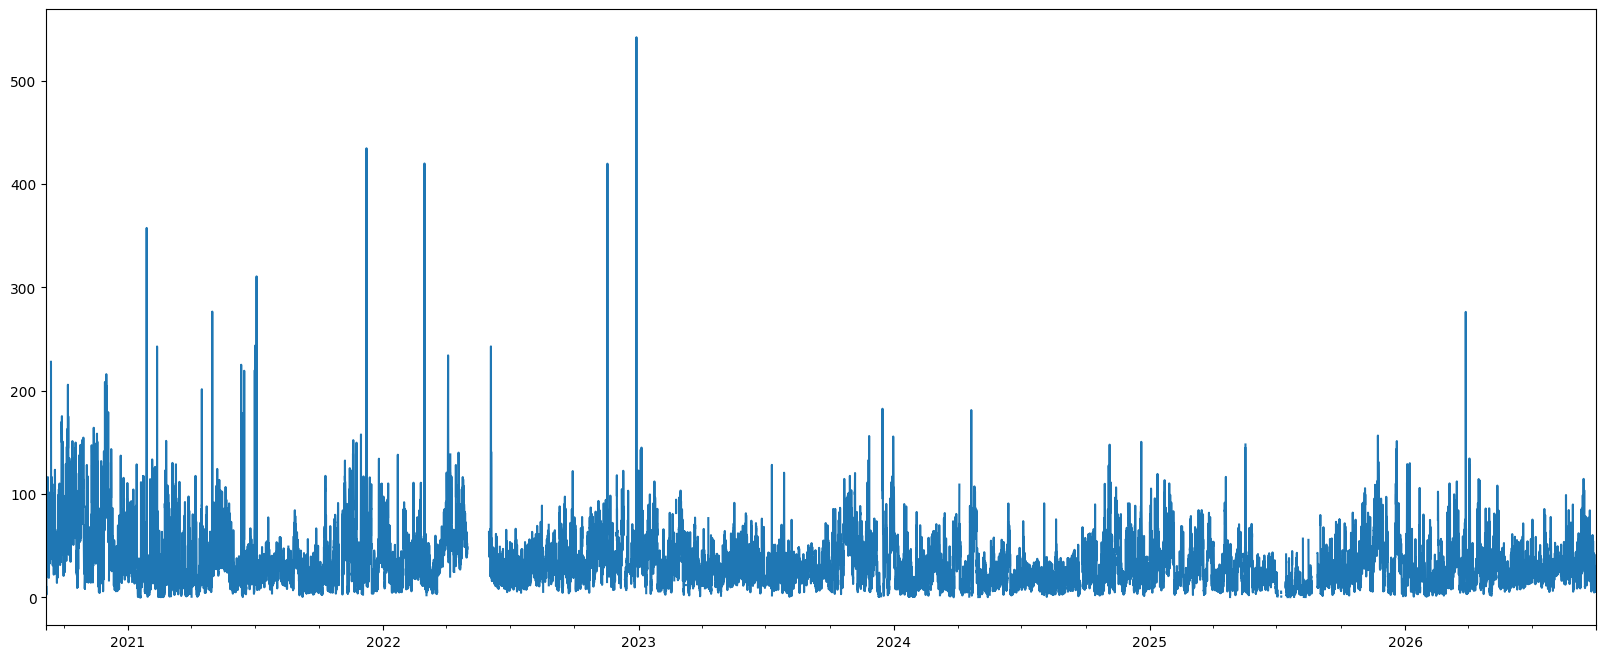

In [113]:
data['pm10'].plot(figsize=(20,8))

In [114]:
data[data['pm10'] > 250]

,temp,humidity,precipitation,pressure,wind_speed,wind_dir,wind_gusts,cloud_cover,pm10,pm2.5,so2,co,no2
2021-01-27 15:00:00,9.4,59,0.0,902.2,20.4,206,62.3,99,357.43,15.17,1.12,222.36,29.63
2021-01-27 16:00:00,8.2,77,1.0,901.9,10.8,201,40.0,100,295.15,18.45,1.15,198.64,32.46
2021-05-01 10:00:00,21.0,42,0.0,921.8,2.3,252,13.7,31,276.47,19.61,3.91,377.20,41.81
2021-07-03 18:00:00,24.2,53,0.0,909.5,16.9,308,35.6,95,310.55,22.26,1.67,119.59,52.00
2021-12-07 21:00:00,11.9,46,0.0,905.0,22.2,148,42.8,87,393.41,62.83,3.14,252.72,24.92
2021-12-07 22:00:00,11.4,47,0.0,904.8,19.7,145,42.1,99,434.52,75.65,3.54,228.14,18.16
2022-02-28 20:00:00,4.9,93,0.6,914.5,17.8,256,31.0,100,419.81,17.77,3.31,1206.56,119.12
2022-02-28 21:00:00,3.9,94,0.4,915.2,9.8,264,33.5,97,271.24,18.42,3.02,875.33,71.45
2022-11-17 10:00:00,8.2,44,0.0,913.2,3.6,264,12.2,95,419.62,28.32,3.75,NaN,218.62
2022-12-28 21:00:00,3.0,80,0.0,925.2,3.8,131,6.1,1,541.96,376.51,5.91,NaN,182.44


In [115]:
corr_table = data.corr(method='spearman')['pm10'].sort_values()

In [116]:
wind_bins = pd.cut(data['wind_speed'], bins=[0, 3, 6, 9, 12, 15, 20, 50], include_lowest=True)
wind_stats = data['pm10'].groupby(wind_bins).agg(['mean', 'count'])
wind_stats

/tmp/ipykernel_645/1947713754.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  wind_stats = data['pm10'].groupby(wind_bins).agg(['mean', 'count'])


,mean,count
wind_speed,,
"(-0.001, 3.0]",39.097845,7586
"(3.0, 6.0]",35.289171,14435
"(6.0, 9.0]",32.731167,12806
"(9.0, 12.0]",29.384825,6821
"(12.0, 15.0]",27.470882,4071
"(15.0, 20.0]",28.174991,3428
"(20.0, 50.0]",36.340904,1316


<Axes: xlabel='wind_speed'>

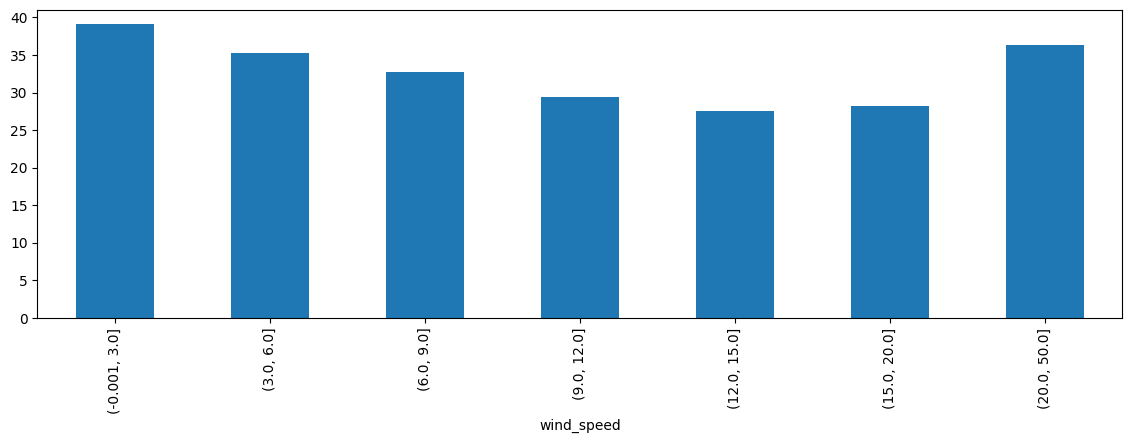

In [117]:
wind_stats['mean'].plot(figsize=(14, 4), kind='bar')

/tmp/ipykernel_645/144307867.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  spec_stats = data['pm10'].groupby(spec_bins).agg(['mean', 'median', 'count'])


<Axes: xlabel='wind_speed'>

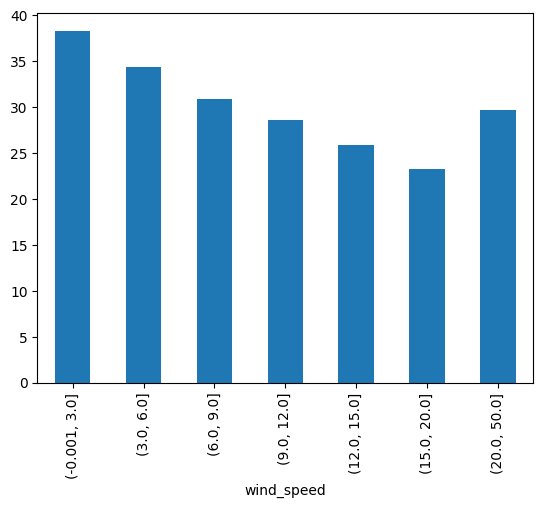

In [118]:
spec_h = data.index.hour.isin(np.arange(12, 16))
spec_wind = data.loc[spec_h, 'wind_speed']
spec_bins = pd.cut(spec_wind, bins=[0, 3, 6, 9, 12, 15, 20, 50], include_lowest=True)
spec_stats = data['pm10'].groupby(spec_bins).agg(['mean', 'median', 'count'])
spec_stats['median'].plot(kind='bar')

In [119]:
spec_stats

,mean,median,count
wind_speed,,,
"(-0.001, 3.0]",46.473811,38.320,824
"(3.0, 6.0]",42.373991,34.400,1759
"(6.0, 9.0]",38.724440,30.845,1696
"(9.0, 12.0]",34.699918,28.570,1459
"(12.0, 15.0]",32.001832,25.885,1092
"(15.0, 20.0]",31.659971,23.265,1032
"(20.0, 50.0]",40.102924,29.640,489


In [120]:
is_rainy = data['precipitation'] > 0
data['pm10'].groupby(is_rainy).agg(['mean', 'median', 'count'])

,mean,median,count
precipitation,,,
False,34.193769,27.805,45368
True,25.618096,20.480,5095


In [121]:
winddir_bins = pd.cut(data['wind_dir'], bins=[0, 45, 90, 135, 180, 225, 270, 315, 360], include_lowest=True)
data['pm10'].groupby(winddir_bins).agg(['mean', 'median', 'count'])

/tmp/ipykernel_645/1066569888.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data['pm10'].groupby(winddir_bins).agg(['mean', 'median', 'count'])


,mean,median,count
wind_dir,,,
"(-0.001, 45.0]",24.740731,21.180,7142
"(45.0, 90.0]",35.926808,29.620,12206
"(90.0, 135.0]",43.802334,38.325,4528
"(135.0, 180.0]",37.864241,31.885,3820
"(180.0, 225.0]",36.141749,29.580,3648
"(225.0, 270.0]",33.621212,26.950,8597
"(270.0, 315.0]",30.543248,24.700,6109
"(315.0, 360.0]",26.320521,21.250,4413


In [122]:
temp_bins = pd.cut(data['temp'], bins=np.arange(-15, 45, 5), include_lowest=True)
data['pm10'].groupby(temp_bins).agg(['mean', 'median', 'count'])

/tmp/ipykernel_645/3766483632.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data['pm10'].groupby(temp_bins).agg(['mean', 'median', 'count'])


,mean,median,count
temp,,,
"(-15.001, -10.0]",19.423553,13.990,76
"(-10.0, -5.0]",18.101257,15.005,676
"(-5.0, 0.0]",29.908033,22.200,3762
"(0.0, 5.0]",34.321005,27.500,7821
"(5.0, 10.0]",34.926028,28.305,8686
"(10.0, 15.0]",36.916906,30.580,8193
"(15.0, 20.0]",33.061227,26.150,8506
"(20.0, 25.0]",32.474198,26.460,6384
"(25.0, 30.0]",31.221649,26.510,4099
